In [1]:

!pip install -q ultralytics scikit-learn seaborn pandas matplotlib


In [2]:

import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from ultralytics import YOLO
from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = 0
else:
    DEVICE = "cpu"

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training will run on CPU.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:

INPUT_DIR = Path("/kaggle/input/datasets/emmarex/plantdisease")

print("Available Kaggle datasets:")

for item in INPUT_DIR.iterdir():
    print(item)

# Find the two bell pepper class folders
healthy_dirs = []
bacterial_dirs = []

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for root, dirs, files in os.walk(INPUT_DIR):
    folder = Path(root)

    # Avoid searching inside unnecessary nested directories
    if not files:
        continue

    images = [
        f for f in files
        if Path(f).suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not images:
        continue

    folder_name = folder.name.lower().replace("_", "").replace(" ", "")

    full_path = str(folder).lower().replace("_", "").replace(" ", "")

    if "pepper" in full_path and "bacterialspot" in full_path:
        bacterial_dirs.append(folder)

    elif "pepper" in full_path and "healthy" in full_path:
        healthy_dirs.append(folder)

print("\nHealthy folders:", healthy_dirs)
print("Bacterial spot folders:", bacterial_dirs)

assert healthy_dirs, "Healthy bell pepper folder not found!"
assert bacterial_dirs, "Bacterial spot folder not found!"


Available Kaggle datasets:
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage
/kaggle/input/datasets/emmarex/plantdisease/plantvillage

Healthy folders: [PosixPath('/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Pepper__bell___healthy'), PosixPath('/kaggle/input/datasets/emmarex/plantdisease/plantvillage/PlantVillage/Pepper__bell___healthy')]
Bacterial spot folders: [PosixPath('/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot'), PosixPath('/kaggle/input/datasets/emmarex/plantdisease/plantvillage/PlantVillage/Pepper__bell___Bacterial_spot')]


Healthy images: 2956
Bacterial spot images: 1994

Total images: 4950


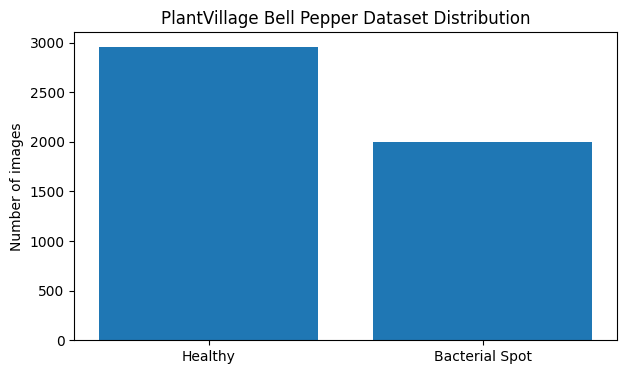

In [4]:

def collect_images(folders):

    images = []

    for folder in folders:
        for file in folder.rglob("*"):

            if file.suffix.lower() in IMAGE_EXTENSIONS:
                images.append(file)

    # Remove duplicate paths
    return sorted(set(images))


healthy_images = collect_images(healthy_dirs)
bacterial_images = collect_images(bacterial_dirs)

print("Healthy images:", len(healthy_images))
print("Bacterial spot images:", len(bacterial_images))

print("\nTotal images:", len(healthy_images) + len(bacterial_images))

# Visualize class distribution
plt.figure(figsize=(7, 4))

plt.bar(
    ["Healthy", "Bacterial Spot"],
    [len(healthy_images), len(bacterial_images)]
)

plt.title("PlantVillage Bell Pepper Dataset Distribution")
plt.ylabel("Number of images")
plt.show()


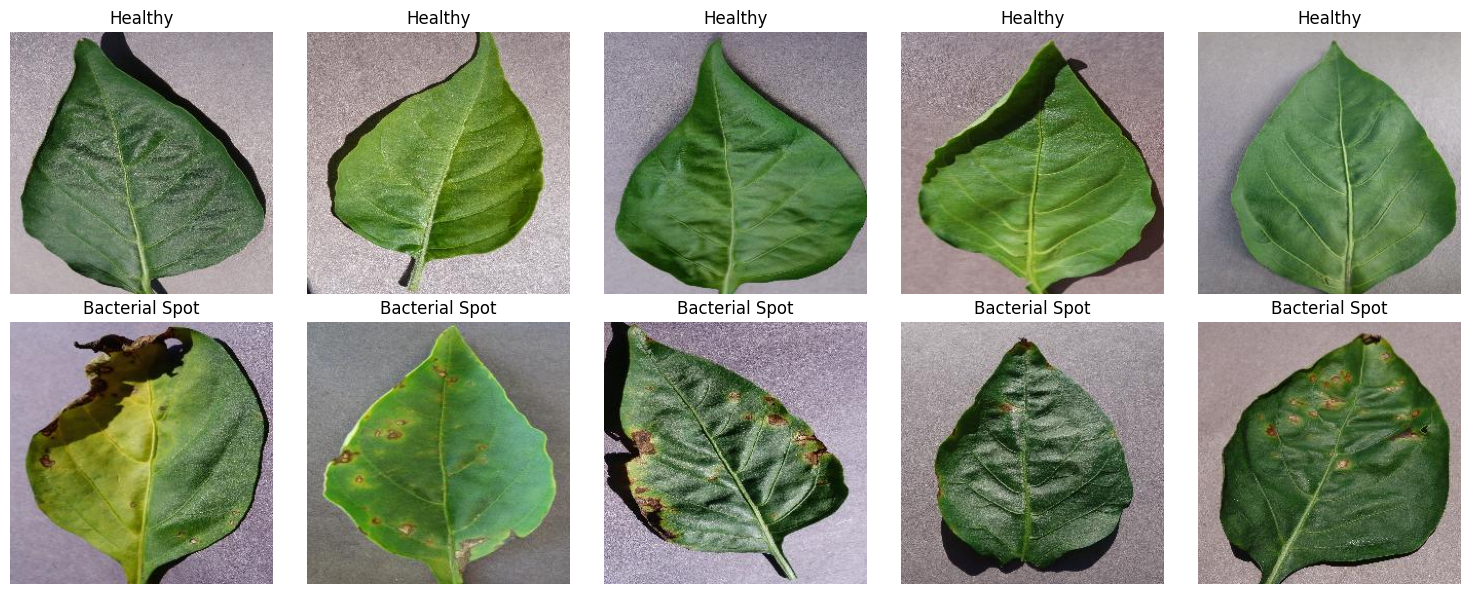

In [5]:

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

samples = [
    (healthy_images, "Healthy"),
    (bacterial_images, "Bacterial Spot")
]

for row, (images, label) in enumerate(samples):

    selected = random.sample(
        images,
        min(5, len(images))
    )

    for col, image_path in enumerate(selected):

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [6]:

DATASET_DIR = Path("/kaggle/working/bell_pepper_dataset")

SPLITS = ["train", "val", "test"]

CLASSES = [
    "Healthy",
    "Bacterial_Spot"
]

# Create dataset directories
for split in SPLITS:
    for class_name in CLASSES:

        folder = DATASET_DIR / split / class_name
        folder.mkdir(parents=True, exist_ok=True)


def split_and_copy(images, class_name):

    # 70% train, 30% temporary
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=SEED
    )

    # Split remaining 30% into 15% validation and 15% test
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=SEED
    )

    split_data = {
        "train": train_images,
        "val": val_images,
        "test": test_images
    }

    for split, files in split_data.items():

        destination = DATASET_DIR / split / class_name

        for index, source in enumerate(files):

            new_name = f"{class_name}_{index:05d}{source.suffix.lower()}"

            shutil.copy2(
                source,
                destination / new_name
            )

    print(f"\n{class_name}")
    print("Train:", len(train_images))
    print("Validation:", len(val_images))
    print("Test:", len(test_images))


split_and_copy(healthy_images, "Healthy")

split_and_copy(bacterial_images, "Bacterial_Spot")

print("\nDataset successfully prepared!")



Healthy
Train: 2069
Validation: 443
Test: 444

Bacterial_Spot
Train: 1395
Validation: 299
Test: 300

Dataset successfully prepared!


In [7]:

for split in SPLITS:

    print(f"\n{split.upper()}")

    for class_name in CLASSES:

        folder = DATASET_DIR / split / class_name

        count = len(list(folder.glob("*")))

        print(f"{class_name}: {count} images")



TRAIN
Healthy: 2069 images
Bacterial_Spot: 1395 images

VAL
Healthy: 443 images
Bacterial_Spot: 299 images

TEST
Healthy: 444 images
Bacterial_Spot: 300 images


In [8]:

MODEL_NAME = "yolo11n-cls.pt"

model = YOLO(MODEL_NAME)

print("Pretrained YOLO Nano Classification model loaded!")


Pretrained YOLO Nano Classification model loaded!


In [9]:

EPOCHS = 50
IMAGE_SIZE = 224
BATCH_SIZE = 32

results = model.train(

    data=str(DATASET_DIR),

    epochs=EPOCHS,

    imgsz=IMAGE_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=2,

    optimizer="AdamW",

    lr0=0.001,

    patience=15,

    weight_decay=0.0005,

    pretrained=True,

    project="/kaggle/working/runs",

    name="bell_pepper_yolo11n",

    seed=SEED,

    deterministic=True,

    plots=True,

    save=True,

    verbose=True
)

print("\nTraining completed!")


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bell_pepper_dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bell_pepper_yolo11n, nbs=64, nms=None, opset=No

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50     0.514G    0.06349          8        224: 100% ━━━━━━━━━━━━ 109/109 10.3it/s 10.6s.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 12/12 16.0it/s 0.8s0.1s
                   all      0.991          1

      Epoch    GPU_mem       loss  Instances       Size
       3/50     0.514G    0.04872          8        224: 100% ━━━━━━━━━━━━ 109/109 10.3it/s 10.6s.3ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 12/12 16.4it/s 0.7s0.1s
                   all      0.991          1

      Epoch    GPU_mem       loss  Instances       Size
       4/50     0.514G    0.06239          8        224: 100% ━━━━━━━━━━━━ 109/109 10.0it/s 10.9s0.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 12/12 16.4it/s 0.7s0.1s
                   all      0.993          1

      Epoch    GPU_mem       loss  Instances       Size
       5/50     0.514G    0.05064          8        224: 100% ━━━━━━━━━━━━ 109/109 10.1it/s 10.8s.3s
               classes  

In [10]:

BEST_MODEL_PATH = (
    Path(results.save_dir) / "weights" / "best.pt"
)

print("Best model:", BEST_MODEL_PATH)

best_model = YOLO(str(BEST_MODEL_PATH))

print("Model classes:", best_model.names)


Best model: /kaggle/working/runs/bell_pepper_yolo11n/weights/best.pt
Model classes: {0: 'Bacterial_Spot', 1: 'Healthy'}


In [11]:

test_results = best_model.val(
    data=str(DATASET_DIR),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

print("\nTest Accuracy (Top-1):", test_results.top1)
print("Test Accuracy (Top-5):", test_results.top5)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /kaggle/working/bell_pepper_dataset/train... found 3464 images in 2/2 classes ✅ 
val: /kaggle/working/bell_pepper_dataset/val... found 742 images in 2/2 classes ✅ 
test: /kaggle/working/bell_pepper_dataset/test... found 744 images in 2/2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 664.7±240.4 MB/s, size: 18.2 KB)
test: Scanning /kaggle/working/bell_pepper_dataset/test... 744 images, 0 corrupt: 100% ━━━━━━━━━━━━ 744/744 2.5Kit/s 0.3s0.2ss
test: New cache created: /kaggle/working/bell_pepper_dataset/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 24/24 13.6it/s 1.8s0.1s
                   all      0.999          1
Speed: 0.1ms preprocess, 1.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /kaggle/working/runs/classify/val

Test Accuracy (Top-1): 0

Class order: ['Bacterial_Spot', 'Healthy']

Classification Report:

                precision    recall  f1-score   support

Bacterial_Spot     0.9967    1.0000    0.9983       300
       Healthy     1.0000    0.9977    0.9989       444

      accuracy                         0.9987       744
     macro avg     0.9983    0.9989    0.9986       744
  weighted avg     0.9987    0.9987    0.9987       744



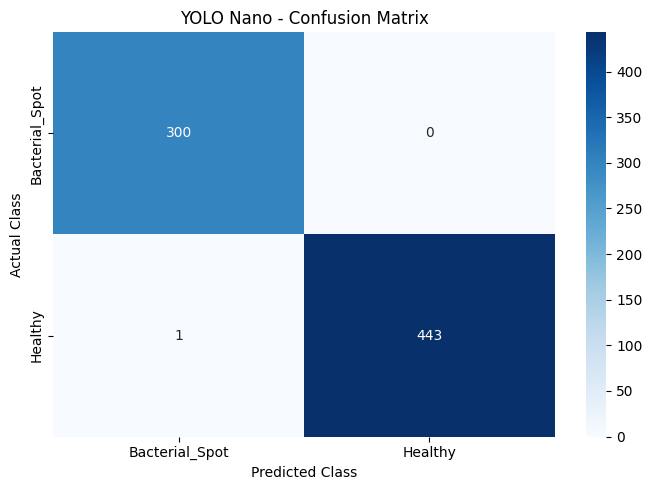


FINAL TEST METRICS
------------------
Accuracy : 0.9987
Precision: 0.9983
Recall   : 0.9989
F1-score : 0.9986


In [12]:

y_true = []
y_pred = []

class_names = [
    best_model.names[i]
    for i in range(len(best_model.names))
]

print("Class order:", class_names)

test_dir = DATASET_DIR / "test"

for true_class in class_names:

    class_folder = test_dir / true_class

    image_paths = [
        p for p in class_folder.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in image_paths:

        prediction = best_model.predict(
            source=str(image_path),
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )[0]

        predicted_index = prediction.probs.top1

        predicted_class = best_model.names[predicted_index]

        y_true.append(true_class)
        y_pred.append(predicted_class)


# Classification report
print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=class_names,
        target_names=class_names,
        digits=4
    )
)


# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("YOLO Nano - Confusion Matrix")

plt.tight_layout()
plt.show()


# Global metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nFINAL TEST METRICS")
print("------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


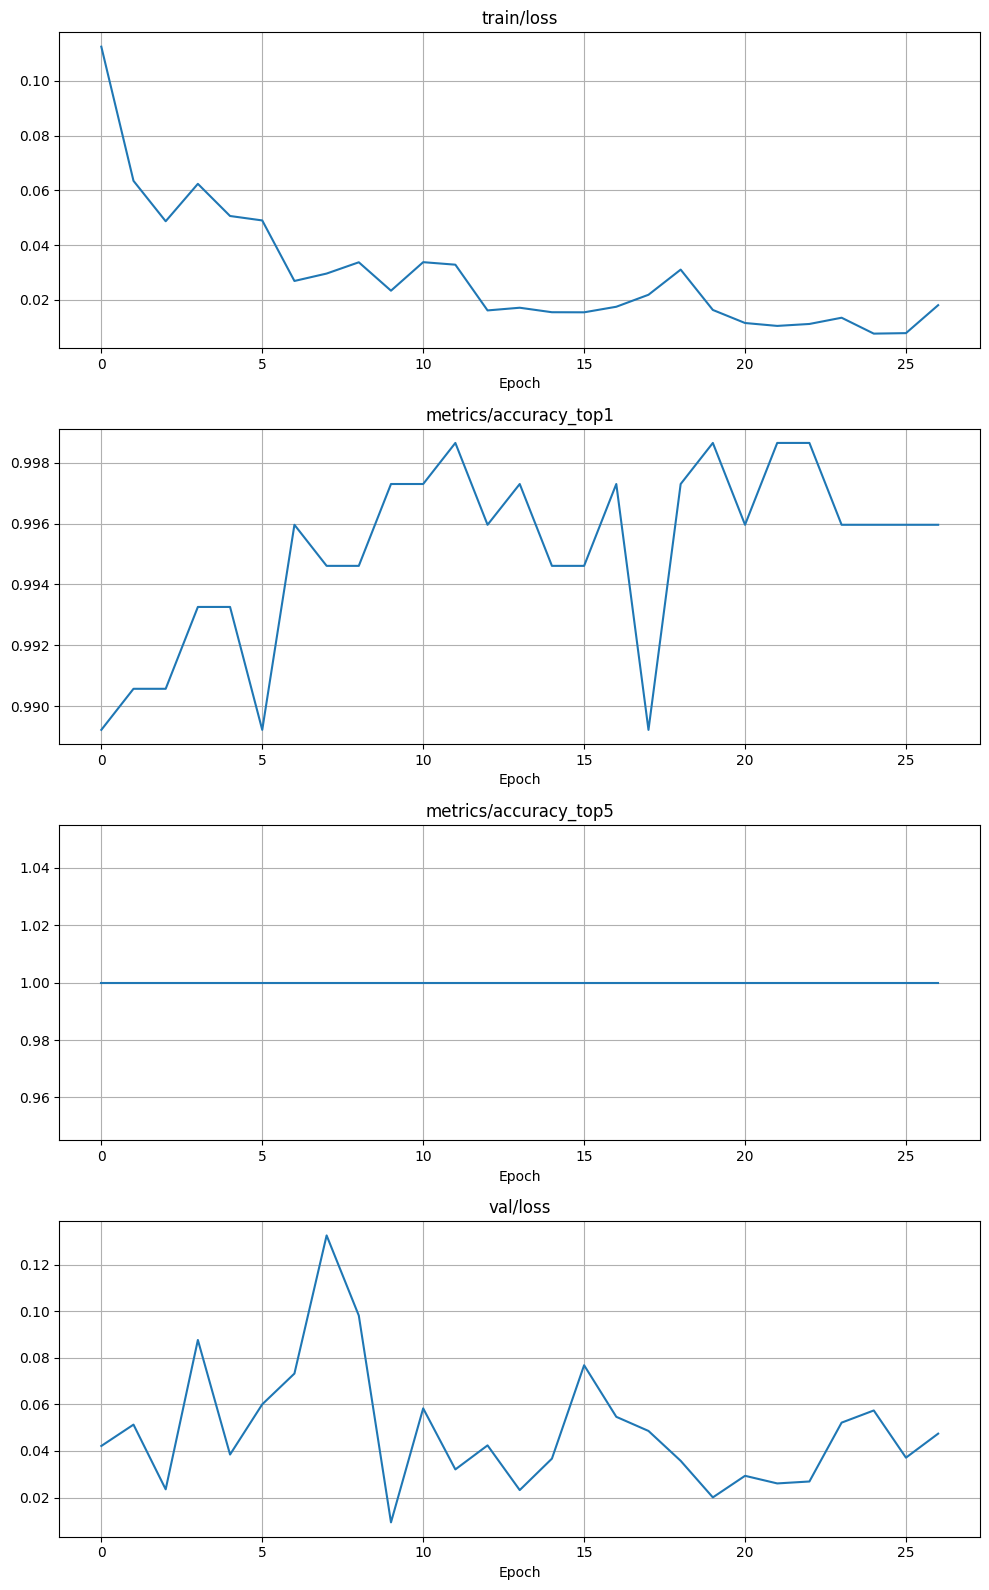

In [13]:

results_csv = Path(results.save_dir) / "results.csv"

history = pd.read_csv(results_csv)

history.columns = history.columns.str.strip()

print(history.columns.tolist())

# Plot available training metrics
metric_columns = [
    col for col in history.columns
    if "acc" in col.lower()
    or "loss" in col.lower()
]

if metric_columns:

    fig, axes = plt.subplots(
        len(metric_columns),
        1,
        figsize=(10, 4 * len(metric_columns))
    )

    if len(metric_columns) == 1:
        axes = [axes]

    for ax, column in zip(axes, metric_columns):

        ax.plot(history[column])
        ax.set_title(column)
        ax.set_xlabel("Epoch")
        ax.grid(True)

    plt.tight_layout()
    plt.show()


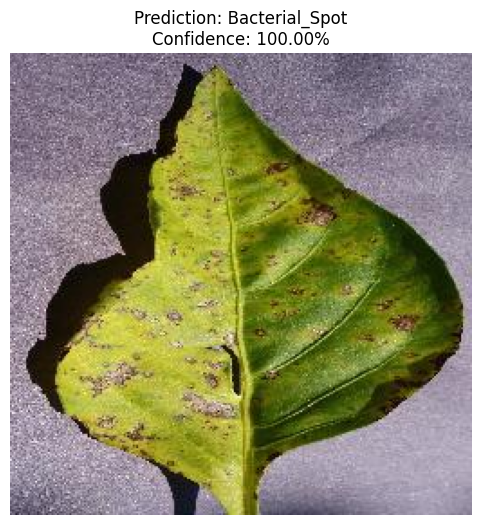

Predicted class: Bacterial_Spot
Confidence: 1.0000


In [14]:

# Select one test image
sample_path = next(
    (DATASET_DIR / "test" / "Bacterial_Spot").glob("*")
)

# Predict
prediction = best_model.predict(
    source=str(sample_path),
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    verbose=False
)[0]

predicted_index = prediction.probs.top1

predicted_class = best_model.names[predicted_index]

confidence = float(prediction.probs.top1conf)

# Display result
image = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)

plt.show()

print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.4f}")


In [15]:

FINAL_MODEL_PATH = "/kaggle/working/best_bell_pepper_yolo.pt"

shutil.copy2(
    BEST_MODEL_PATH,
    FINAL_MODEL_PATH
)

print("Model saved successfully!")
print("Location:", FINAL_MODEL_PATH)

print(
    "Model size:",
    round(os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024), 2),
    "MB"
)


Model saved successfully!
Location: /kaggle/working/best_bell_pepper_yolo.pt
Model size: 3.04 MB


In [16]:

onnx_path = best_model.export(
    format="onnx",
    imgsz=IMAGE_SIZE
)

print("ONNX model exported:", onnx_path)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 0.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/bell_pepper_yolo11n/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 2) (3.0 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 350ms
Prepared 2 packages in 259ms
Installed 2 packages in 24ms
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.6

In [19]:
!ls -lh /kaggle/working/best_bell_pepper_yolo.pt
!ls -lh /kaggle/working/runs/bell_pepper_yolo11n/weights/

-rw-r--r-- 1 root root 3.1M Nov 16 21:25 /kaggle/working/best_bell_pepper_yolo.pt
total 12M
-rw-r--r-- 1 root root 5.9M Nov 16 21:25 best.onnx
-rw-r--r-- 1 root root 3.1M Nov 16 21:25 best.pt
-rw-r--r-- 1 root root 3.1M Nov 16 21:25 last.pt
